In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA PREPARATION 

1.Load the file using pandas library.

r is to prevent any unicode error 

2.File is xls format and is converted to csv using .to_csv.

3.Index = False - We don't want to include the first column as the index

In [2]:
df_raw = pd.read_excel(r'C:\Users\LENOVO\OneDrive\Desktop\DATA ANALYTICS\7.MACHINE LEARNING\Breast_Cancer_pred\Breast_Cancer_Prediction.xlsx')
df_raw.to_csv('Breast_Cancer_Prediction.csv', index=False)

In [3]:
df_raw.head(10)

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919
5,100006,22,Female,18.8,No,No,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,172,270,No,3,Yes,51320
6,100007,41,Female,31.8,Yes,No,Yes,High,No,Post,...,Normal,Benign,No Cancer,0,176,297,No,7,No,47235
7,100008,72,Male,23.8,No,Yes,No,High,No,Post,...,Normal,Benign,No Cancer,0,164,184,No,5,Yes,102525
8,100009,21,Female,26.1,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,164,238,No,0,Not Applicable,47668
9,100010,49,Female,29.7,Yes,No,Yes,Moderate,No,Pre,...,Normal,Benign,No Cancer,0,177,300,No,0,Yes,83068


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10000 non-null  int64  
 1   Age                     10000 non-null  int64  
 2   Gender                  10000 non-null  str    
 3   BMI                     9700 non-null   float64
 4   Family_History          10000 non-null  str    
 5   Smoking                 10000 non-null  str    
 6   Alcohol_Consumption     9700 non-null   str    
 7   Physical_Activity       9700 non-null   str    
 8   Hormone_Therapy         9700 non-null   str    
 9   Menopause_Status        10000 non-null  str    
 10  Genetic_Mutation        10000 non-null  str    
 11  Tumor_Size_cm           9700 non-null   float64
 12  Lymph_Node_Involvement  10000 non-null  str    
 13  Mammogram_Result        10000 non-null  str    
 14  Biopsy_Result           10000 non-null  str    
 1

In [5]:
df_raw.shape

(10000, 23)

In [6]:
df_raw.describe(include = 'all')

,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
count,10000.00000,10000.000000,10000,9700.000000,10000,10000,9700,9700,9700,10000,...,10000,10000,10000,10000.000000,10000.000000,10000.000000,10000,10000.000000,10000,10000.000000
unique,NaN,NaN,2,NaN,2,2,2,3,2,2,...,3,2,5,NaN,NaN,NaN,2,NaN,3,NaN
top,NaN,NaN,Female,NaN,No,No,No,Moderate,No,Post,...,Normal,Benign,No Cancer,NaN,NaN,NaN,No,NaN,Yes,NaN
freq,NaN,NaN,9277,NaN,6979,7462,6319,4379,7704,5509,...,6481,8067,8067,NaN,NaN,NaN,8296,NaN,4514,NaN
mean,105000.50000,52.033800,NaN,27.051227,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.193300,134.811100,214.071500,NaN,3.535200,NaN,82337.305000
std,2886.89568,18.789517,NaN,4.494501,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.394906,26.174742,49.242034,NaN,2.282385,NaN,39102.629984
min,100001.00000,20.000000,NaN,11.100000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,90.000000,130.000000,NaN,0.000000,NaN,15002.000000
25%,102500.75000,36.000000,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,112.000000,172.000000,NaN,2.000000,NaN,48145.750000
50%,105000.50000,52.000000,NaN,27.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,135.000000,213.000000,NaN,4.000000,NaN,81813.500000
75%,107500.25000,68.000000,NaN,30.100000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,157.000000,257.000000,NaN,6.000000,NaN,116217.500000


In [7]:
df_raw.columns.tolist()

['Patient_ID',
 'Age',
 'Gender',
 'BMI',
 'Family_History',
 'Smoking',
 'Alcohol_Consumption',
 'Physical_Activity',
 'Hormone_Therapy',
 'Menopause_Status',
 'Genetic_Mutation',
 'Tumor_Size_cm',
 'Lymph_Node_Involvement',
 'Mammogram_Result',
 'Biopsy_Result',
 'Cancer_Stage',
 'Cancer',
 'Blood_Pressure',
 'Cholesterol',
 'Diabetes',
 'Exercise_Days_Per_Week',
 'Breastfeeding_History',
 'Annual_Income_USD']

In [10]:
df_raw.nunique().sort_values()

Gender                        2
Alcohol_Consumption           2
Smoking                       2
Family_History                2
Lymph_Node_Involvement        2
Genetic_Mutation              2
Menopause_Status              2
Hormone_Therapy               2
Biopsy_Result                 2
Cancer                        2
Diabetes                      2
Mammogram_Result              3
Physical_Activity             3
Breastfeeding_History         3
Cancer_Stage                  5
Exercise_Days_Per_Week        8
Age                          65
Blood_Pressure               91
Cholesterol                 171
BMI                         280
Tumor_Size_cm               728
Annual_Income_USD          9645
Patient_ID                10000
dtype: int64

BY THE END OF AN EXPLORATORY DATA ANALYSIS WE SHOUL HAVE :-

    A data dictionary (meaning, units, valid ranges)

    A quality report (missingness, duplicates, outliers, parsing issues)

    A leakage/confound list (features to block or constrain)

    A preprocessing plan (encoding, scaling, imputation strategy)

    A baseline benchmark (even if intentionally simple)

    A reproducible notebook/script (same results on re-run)

DATA CLEANING 

1.Ceate a Copy of the dataset. so that the data cleaning doesn't affect the original file



In [11]:
df = df_raw.copy() #copy of the dataframe

2.Remove Irrelevant Column

In [12]:
df.drop('Patient_ID', axis=1, inplace=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31588\1217584191.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Patient_ID', axis=1, inplace=True)


3.Remove Duplicate Rows 


In [13]:
df.drop_duplicates()

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,71,Female,27.2,Yes,Yes,Yes,High,No,Post,Positive,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,34,Male,26.0,No,No,No,High,No,Post,Negative,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,80,Female,20.7,No,No,No,High,No,Pre,Negative,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,Negative,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,Negative,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,84,Female,31.4,No,No,Yes,High,No,Post,Positive,...,Normal,Benign,No Cancer,0,117,166,No,5,Not Applicable,46779
9996,43,Female,24.7,No,Yes,No,Moderate,Yes,Pre,Negative,...,Abnormal,Benign,No Cancer,0,116,169,No,7,No,110807
9997,23,Female,26.2,Yes,No,Yes,Moderate,No,Pre,Negative,...,Normal,Benign,No Cancer,0,140,214,No,6,No,126164
9998,44,Female,21.8,No,No,No,Moderate,No,Post,Positive,...,Abnormal,Benign,No Cancer,0,153,175,No,4,Not Applicable,89761


4.Check for Missing Columns

In [14]:
df.isna().sum()

Age                         0
Gender                      0
BMI                       300
Family_History              0
Smoking                     0
Alcohol_Consumption       300
Physical_Activity         300
Hormone_Therapy           300
Menopause_Status            0
Genetic_Mutation            0
Tumor_Size_cm             300
Lymph_Node_Involvement      0
Mammogram_Result            0
Biopsy_Result               0
Cancer_Stage                0
Cancer                      0
Blood_Pressure              0
Cholesterol                 0
Diabetes                    0
Exercise_Days_Per_Week      0
Breastfeeding_History       0
Annual_Income_USD           0
dtype: int64

In [15]:
#Made a list of columns with atleast one missing value
df.columns[df.isna().any()].tolist()

['BMI',
 'Alcohol_Consumption',
 'Physical_Activity',
 'Hormone_Therapy',
 'Tumor_Size_cm']

In [16]:
# Percentage missing in each column
missing_columns = df.isna().mean().mul(100).round(2)
print(missing_columns[missing_columns > 0].sort_values(ascending=False))

BMI                    3.0
Alcohol_Consumption    3.0
Physical_Activity      3.0
Hormone_Therapy        3.0
Tumor_Size_cm          3.0
dtype: float64


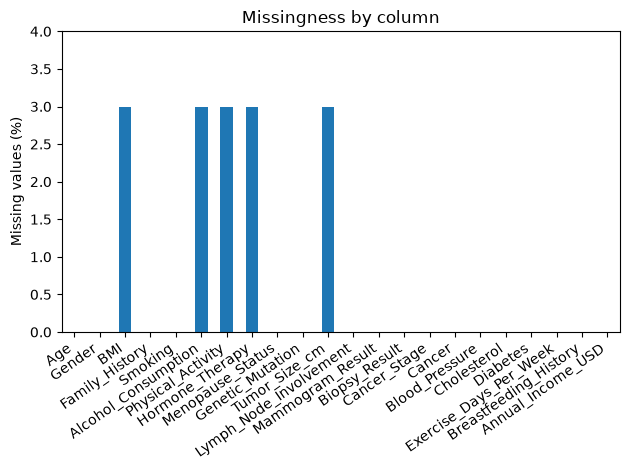

In [17]:
missing_columns.plot(kind="bar", ylabel="Missing values (%)",
                 title="Missingness by column", ylim=(0, 4))
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [18]:
#percentage of missing values in each rows
missing_rows = df.isna().mean().mul(100).round(2)
print(missing_rows.value_counts().sort_index())

0.0    17
3.0     5
Name: count, dtype: int64


In [19]:
missing_columns = df.columns[df.isna().any()]
# How many rows have any missing values?
df.isna().any(axis=1).sum()
# Check whether the missing fields occur together
df.loc[df[missing_columns].isna().any(axis=1), missing_columns].isna().sum()

BMI                    300
Alcohol_Consumption    300
Physical_Activity      300
Hormone_Therapy        300
Tumor_Size_cm          300
dtype: int64

5.Check for Impossible Values 

In [20]:
#checking for the all the numerical columns
num_list = df.select_dtypes(include="number").columns
num_list

Index(['Age', 'BMI', 'Tumor_Size_cm', 'Cancer', 'Blood_Pressure',
       'Cholesterol', 'Exercise_Days_Per_Week', 'Annual_Income_USD'],
      dtype='str')

Use boxplots to determine the outliers in each of them(numerical values)

Boxplots -the middle 50% of values (Q1 to Q3). 

The line inside is the median.

Whiskers: extend to the furthest values within 1.5 × IQR of the box (IQR = Q3 − Q1).

Dots beyond the whiskers: potential outliers.

In [21]:
num_list = df[num_list].drop(columns=['Cancer'],errors='ignore')

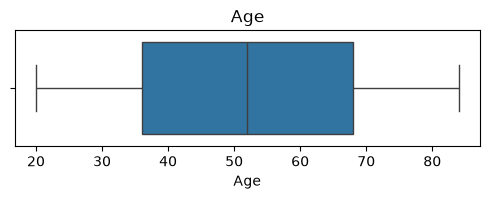

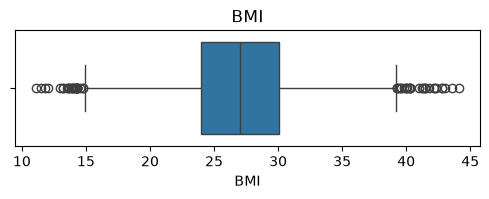

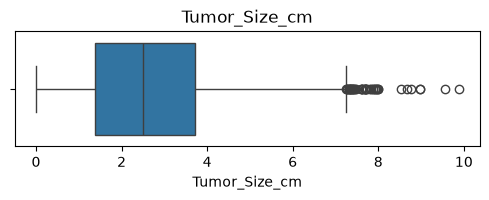

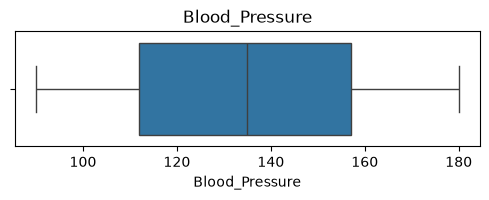

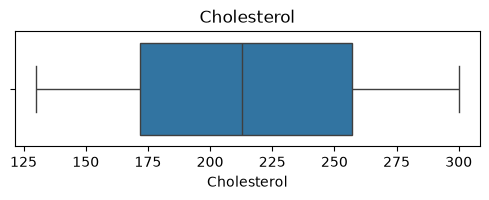

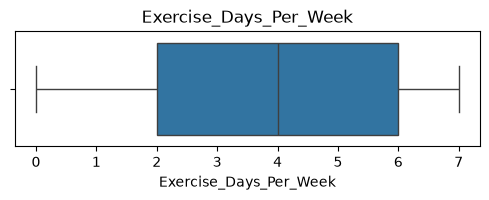

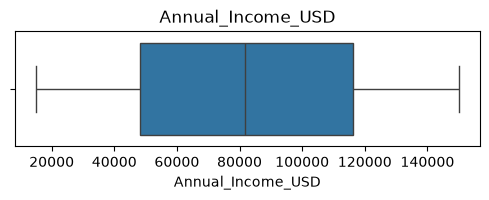

Age: 0 outliers (below -12.00 or above 116.00)
BMI: 57 outliers (below 14.85 or above 39.25)
Tumor_Size_cm: 44 outliers (below -2.16 or above 7.25)
Blood_Pressure: 0 outliers (below 44.50 or above 224.50)
Cholesterol: 0 outliers (below 44.50 or above 384.50)
Exercise_Days_Per_Week: 0 outliers (below -4.00 or above 12.00)
Annual_Income_USD: 0 outliers (below -53961.88 or above 218325.12)


In [22]:
for col in num_list:
    plt.figure(figsize=(6, 1.5))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()
    
    
    
    
for col in num_list:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_outliers} outliers (below {lower:.2f} or above {upper:.2f})")

UNIVARITE, BIVARIATE AN MULTIVARIATE ANALYSIS


<Axes: xlabel='Cancer', ylabel='count'>

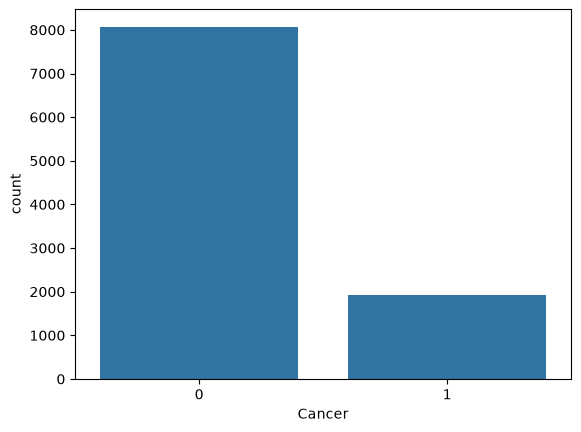

In [23]:
# Plot the distribution of the target variable
sns.countplot(x='Cancer',data =df)

Let's look at the dsitribution of numerical and categorical variables 

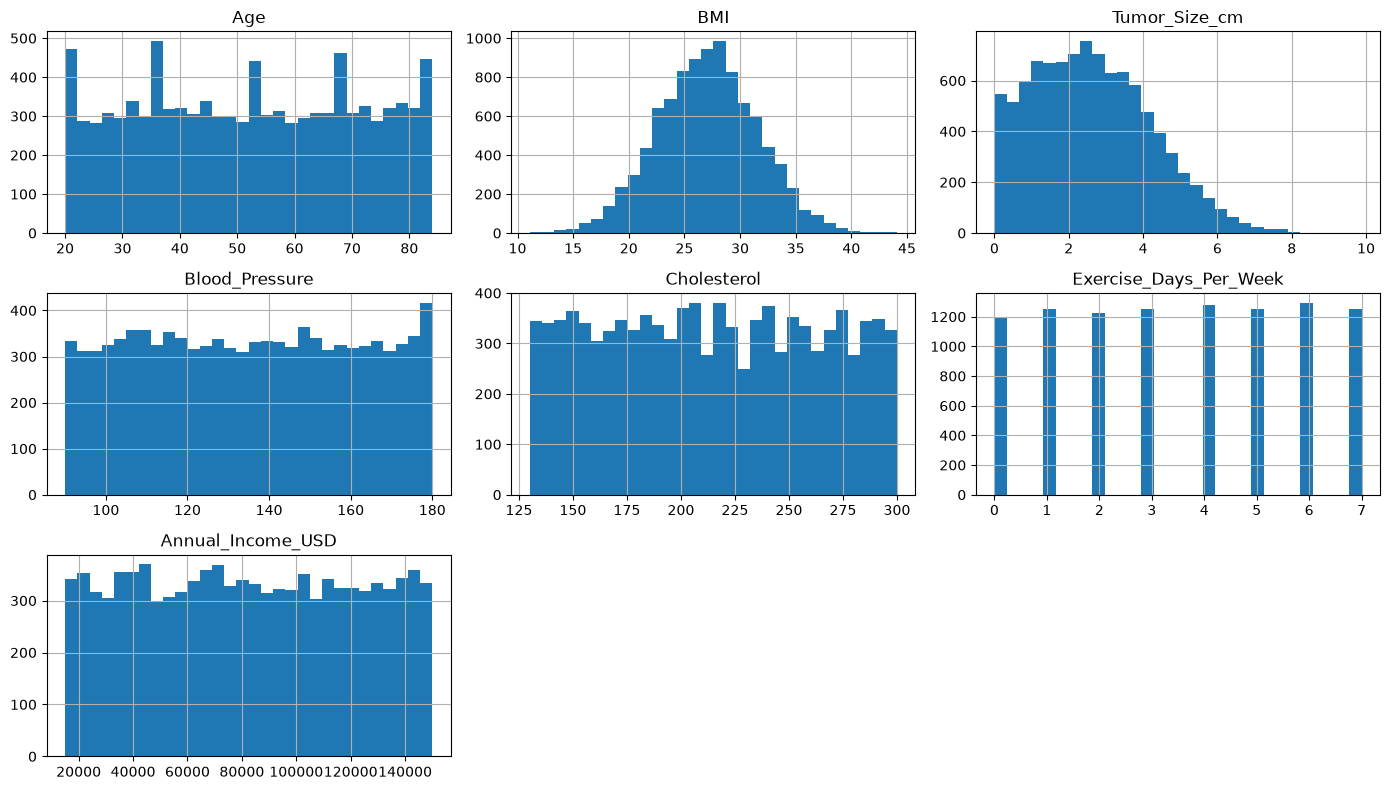

In [24]:
#numerical columns correlation
num_cols = ['Age','BMI','Tumor_Size_cm','Blood_Pressure','Cholesterol',
            'Exercise_Days_Per_Week','Annual_Income_USD']
df[num_cols].hist(bins=30, figsize=(14, 8)); plt.tight_layout(); plt.show()

In [25]:
# How many unique values does each column have?
df.nunique().sort_values()

Gender                       2
Family_History               2
Alcohol_Consumption          2
Smoking                      2
Hormone_Therapy              2
Lymph_Node_Involvement       2
Genetic_Mutation             2
Menopause_Status             2
Cancer                       2
Biopsy_Result                2
Diabetes                     2
Physical_Activity            3
Breastfeeding_History        3
Mammogram_Result             3
Cancer_Stage                 5
Exercise_Days_Per_Week       8
Age                         65
Blood_Pressure              91
Cholesterol                171
BMI                        280
Tumor_Size_cm              728
Annual_Income_USD         9645
dtype: int64

In [26]:
#Categorical Columns 
cat_col = df.select_dtypes(include=['category','object']).columns.tolist()
cat_col

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31588\4272534820.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df.select_dtypes(include=['category','object']).columns.tolist()


['Gender',
 'Family_History',
 'Smoking',
 'Alcohol_Consumption',
 'Physical_Activity',
 'Hormone_Therapy',
 'Menopause_Status',
 'Genetic_Mutation',
 'Lymph_Node_Involvement',
 'Mammogram_Result',
 'Biopsy_Result',
 'Cancer_Stage',
 'Diabetes',
 'Breastfeeding_History']

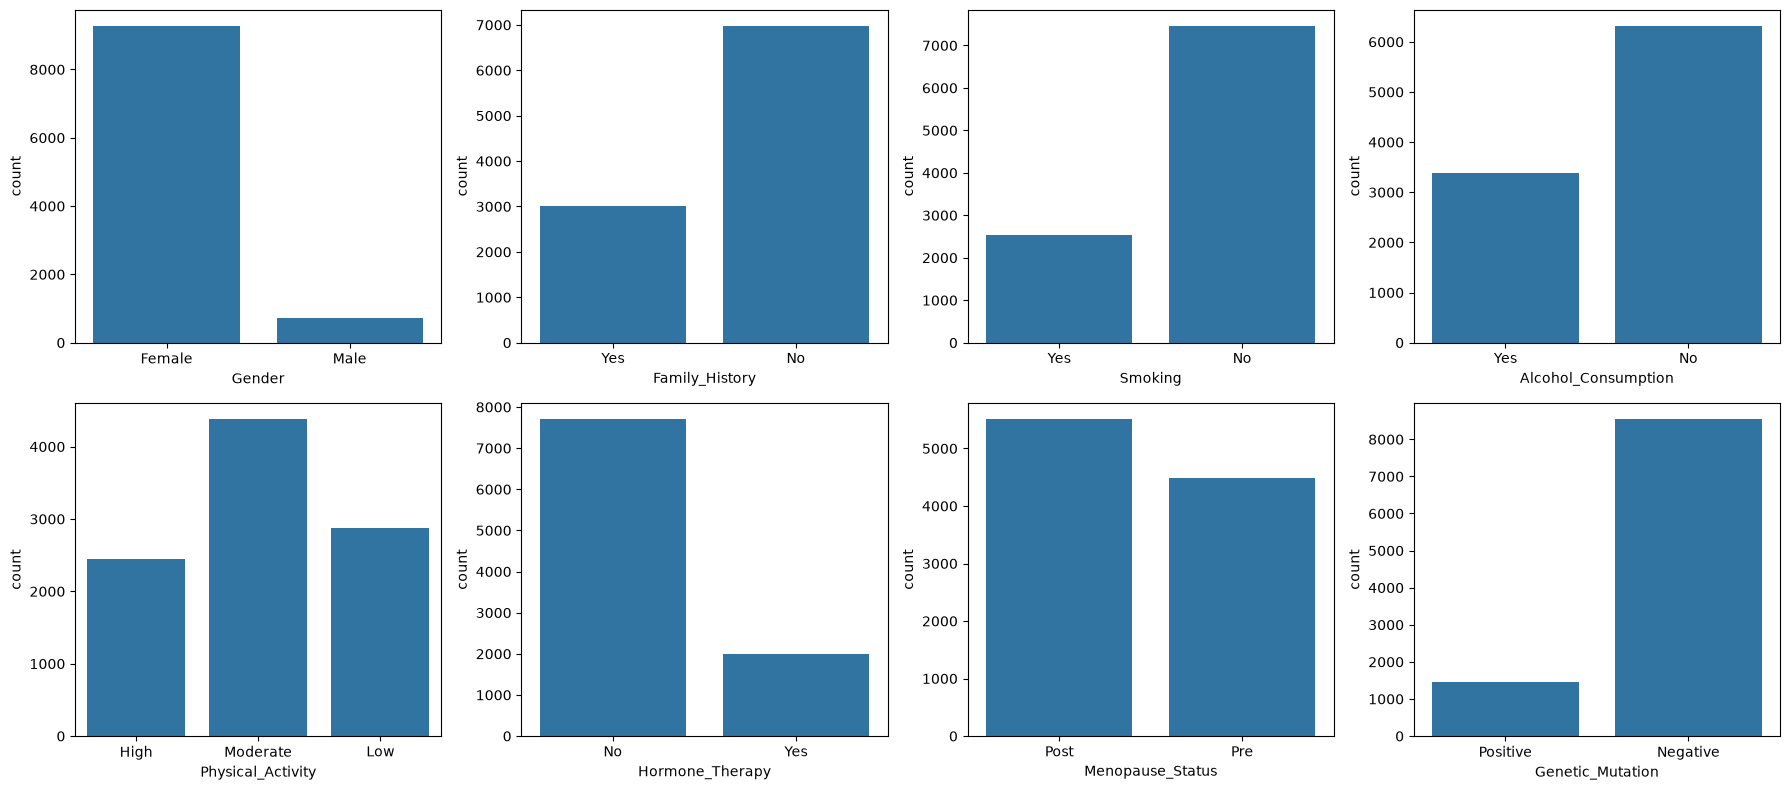

In [27]:
fig, axes = plt.subplots(2,4, figsize=(18, 8))
for ax, c in zip(axes.flat, cat_col):
    sns.countplot(x=c, data=df, ax=ax)
plt.tight_layout(); plt.show()

'Lymph_Node_Involvement','Mammogram_Result','Biopsy_Result','Cancer_Stage','Diabetes',
'Breastfeeding_History' # check why these values didn't have a plot 

DATA PREPROCESSING 

Imputation or removal: Decide whether to fill in missing values with mean/median values or domain-specific imputation strategies — or to remove rows/columns with too many missing entries.

In [28]:
#After checking for missing values, we found that all of the missing value are missing together instead of randomly. So we can drop the rows with missing values.
#Instead of removal we decided to drop them rather than imputation because the number of rows with missing values is very small compared to the total number of rows in the dataset.
missing_columns = df.columns[df.isna().any()]
df.dropna(subset=missing_columns)

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,71,Female,27.2,Yes,Yes,Yes,High,No,Post,Positive,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,34,Male,26.0,No,No,No,High,No,Post,Negative,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,80,Female,20.7,No,No,No,High,No,Pre,Negative,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,Negative,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,Negative,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,84,Female,31.4,No,No,Yes,High,No,Post,Positive,...,Normal,Benign,No Cancer,0,117,166,No,5,Not Applicable,46779
9996,43,Female,24.7,No,Yes,No,Moderate,Yes,Pre,Negative,...,Abnormal,Benign,No Cancer,0,116,169,No,7,No,110807
9997,23,Female,26.2,Yes,No,Yes,Moderate,No,Pre,Negative,...,Normal,Benign,No Cancer,0,140,214,No,6,No,126164
9998,44,Female,21.8,No,No,No,Moderate,No,Post,Positive,...,Abnormal,Benign,No Cancer,0,153,175,No,4,Not Applicable,89761
